In [1]:
import anndata as ad
import squidpy as sq
import cellcharter as cc
import pandas as pd
import scanpy as sc
import scvi
import numpy as np
import matplotlib.pyplot as plt
from lightning.pytorch import seed_everything

seed_everything(12345)

import os
import bbknn
from scipy import sparse
import matplotlib.pyplot as plt
from typing import List, Tuple
from typing import Union, List

/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/anndata/__init__.py:44: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  return module_get_attr_redirect(attr_n

In [2]:
adata = sc.read("./IWD_plaque.h5ad")

In [3]:
adata.obsm['spatial'] = adata.obsm['X_spatial']

adata

AnnData object with n_obs × n_vars = 9988 × 4495
    obs: 'orig.ident', 'nCount_Xenium', 'nFeature_Xenium', 'nucleus_area', 'cell_area', 'nc_ratio', 'Cell_Anno', 'group', 'Type', 'nCount_SCT', 'nFeature_SCT', 'niche', 'domain', 'plaque', 'barcode'
    obsm: 'X_pca', 'X_spatial', 'X_umap', 'spatial'

In [4]:

def get_cells_by_distance_to_target(
    adata,
    cell_type_col: str = "Celltype",
    target_cell: str = "A",
    radius_ranges: List[Tuple[float, float]] = [(0, 10), (10, 50), (50, 100), (100, 200)],
    slide_col: str = "sample"  # 
):
   
    adata = adata.copy()
    
    if slide_col is None:
        raise ValueError("slide_col must be specified to run the per-slide calculation")
    
    # 
    slides = adata.obs[slide_col].unique()
    all_results = []
    
    for slide in slides:
        # 
        slide_mask = adata.obs[slide_col] == slide
        adata_slide = adata[slide_mask].copy()
        
        # 
        slide_result = _calculate_min_distance_per_slide(
            adata_slide, 
            cell_type_col, 
            target_cell, 
            radius_ranges
        )
        
        if slide_result is not None:
            # 
            slide_result.obs['slide'] = slide
            all_results.append(slide_result)
    
    if not all_results:
        print("Warning: no target cells were found")
        return None
    
    # 
    adata_sub = sc.concat(all_results)
    
    # 
    non_target_mask = adata_sub.obs[cell_type_col] != target_cell
    adata_sub = adata_sub[non_target_mask].copy()
    
    return adata_sub

def _calculate_min_distance_per_slide(
    adata,
    cell_type_col: str,
    target_cell: str,
    radius_ranges: List[Tuple[float, float]]
):
   
    from scipy.spatial import distance
    
    # 
    target_mask = adata.obs[cell_type_col] == target_cell
    target_coords = adata[target_mask].obsm['spatial']
    target_names = adata[target_mask].obs_names.tolist()
    
    if len(target_coords) == 0:
        print(f"Warning: target cell not found in the current slide: '{target_cell}'")
        return None
    
    # 
    all_coords = adata.obsm['spatial']
    all_names = adata.obs_names.tolist()
    
    # 
    min_distances = np.zeros(len(all_coords))
    nearest_targets = [None] * len(all_coords)
    
    # 
    for i, cell_coord in enumerate(all_coords):
        min_dist = float('inf')
        nearest_target = None
        
        # 
        for j, target_coord in enumerate(target_coords):
            dist = distance.euclidean(cell_coord, target_coord)
            if dist < min_dist:
                min_dist = dist
                nearest_target = target_names[j]
        
        min_distances[i] = min_dist
        nearest_targets[i] = nearest_target
    
    # 
    adata.obs['min_distance'] = min_distances
    adata.obs['nearest_target'] = nearest_targets
    
    radius_labels = []
    sorted_ranges = sorted(radius_ranges, key=lambda x: x[0])  # 
    
    for d in min_distances:
        label = None
        for r_min, r_max in sorted_ranges:
            if r_min <= d < r_max:
                label = f"{r_min}-{r_max}"
                break
        radius_labels.append(label)
    
    adata.obs['radius_range'] = radius_labels
    
    # 
    valid_mask = ~adata.obs['radius_range'].isna()
    valid_cells = adata[valid_mask].copy()
    
    return valid_cells

In [53]:
#
adata_sub = get_cells_by_distance_to_target(
    adata_lesions,
    cell_type_col="Cell_Anno",
    target_cell="Inf EC",##
    radius_ranges=[(0, 20), (20, 100), (100, 200), (200, 500)],
    slide_col="group"  # 
)

In [35]:
adata_sub.obs['group'].unique()

AnnData object with n_obs × n_vars = 9030 × 4495
    obs: 'orig.ident', 'nCount_Xenium', 'nFeature_Xenium', 'nucleus_area', 'cell_area', 'nc_ratio', 'Cell_Anno', 'group', 'Type', 'nCount_SCT', 'nFeature_SCT', 'niche', 'domain', 'plaque', 'barcode', 'min_distance', 'nearest_target', 'radius_range', 'slide'
    uns: 'radius_range_colors', 'Cell_Anno_colors'
    obsm: 'X_pca', 'X_spatial', 'X_umap', 'spatial'

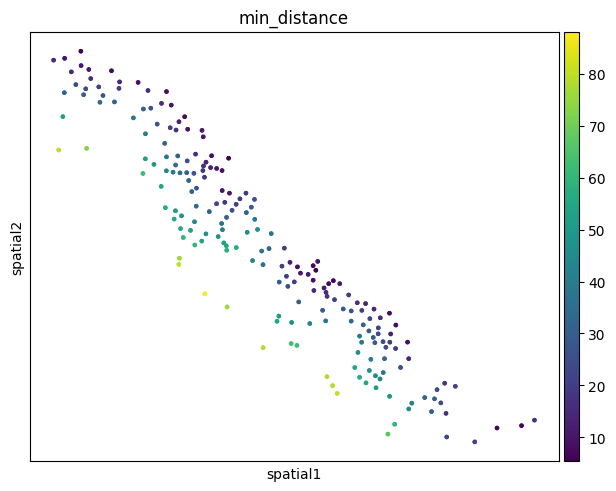

In [56]:
sq.pl.spatial_scatter(
    adata_sub,
    library_key='group',
    library_id="CWD297",
    shape=None,
    color=[
        "min_distance",
    ],
    wspace=0.4,
)
#plt.savefig( './1.pdf', bbox_inches='tight',  dpi=500)   

In [50]:
adata_sub.obs.to_csv("./vertical_neighborhood.csv")

In [67]:
import numpy as np
import scanpy as sc
from scipy.spatial.distance import cdist

def calculate_vertical_distance(
    adata,
    niche_col="banksy_niche",
    source_niche="niche_3",
    target_niche=["niche_1", "niche_4", "niche_6"],
    slide_col="group",
    coord_key="spatial"
):
 
    source_mask = adata.obs[niche_col] == source_niche
    adata_vertical = adata[source_mask].copy()
    
    # 
    target_mask = adata.obs[niche_col].isin(target_niche)
    
    # 
    if not target_mask.any():
        print(f"Warning: no target niche cells found: {target_niche}")
        adata_vertical.obs['vertical_distance'] = np.nan
        return adata_vertical
    
  
    if coord_key not in adata.obsm:
        raise KeyError(f"spatial coordinate key not found in adata.obsm: '{coord_key}'")
    coords = adata.obsm[coord_key]
    
    # 
    slides = adata.obs[slide_col].unique()
    
    # 
    vertical_distances = np.full(adata_vertical.shape[0], np.nan)
    
    for slide in slides:
        # 
        slide_mask = adata.obs[slide_col] == slide
        
        # 
        source_in_slide = slide_mask & source_mask
        
        # 
        target_in_slide = slide_mask & target_mask
        
        if not source_in_slide.any() or not target_in_slide.any():
            continue

        source_coords = coords[source_in_slide]
        target_coords = coords[target_in_slide]

        distances = cdist(source_coords, target_coords)

        min_distances = np.min(distances, axis=1)

        slide_source_indices = adata.obs.index[source_in_slide]
        vertical_mask = adata_vertical.obs.index.isin(slide_source_indices)
        vertical_distances[vertical_mask] = min_distances

    adata_vertical.obs['vertical_distance'] = vertical_distances
    
    return adata_vertical



In [68]:


adata_vertical = calculate_vertical_distance(
    adata,
    niche_col="banksy_niche",
    source_niche="niche_3",
    target_niche=["niche_1", "niche_4", "niche_6"],
    slide_col="group"
)

In [16]:
########################
##
from typing import Optional, Union
import numpy as np
import pandas as pd
import scanpy as sc
from sklearn.cluster import DBSCAN
from scipy.spatial import distance
from tqdm import tqdm

def identify_lesions(
    adata: sc.AnnData,
    niche_col: str = "banksy_niche",
    target_niche: str = "niche_3",
    slide_col: str = "sample",
    eps: float = 150,
    min_cells_per_lesion: int = 30,
    distance_percentile: float = 95,
    return_subset: bool = True,
    random_seed: Optional[int] = None
) -> Union[sc.AnnData, None]:
  
    if random_seed is not None:
        np.random.seed(random_seed)
    

    adata = adata.copy()
    adata.obs['lesion_id'] = 'isolated'
    adata.obs['distance_to_centroid'] = np.nan
    

    target_mask = adata.obs[niche_col] == target_niche
    if not any(target_mask):
        print(f"Warning: no {target_niche} cells were found")
        return None
    
    adata_target = adata[target_mask].copy()
    

    for slide in tqdm(adata_target.obs[slide_col].unique(), desc="Processing slides"):
        slide_mask = (adata_target.obs[slide_col] == slide)
        adata_slide = adata_target[slide_mask].copy()
        coords = adata_slide.obsm['spatial'][:, :2]  # 
        
        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_cells_per_lesion
        )
        clusters = dbscan.fit_predict(coords)
 
        for cluster_id in np.unique(clusters):
            if cluster_id == -1:
                continue  # 
            cluster_mask = (clusters == cluster_id)
            lesion_id = f"{slide}_lesion_{cluster_id}"
            adata_slide.obs.loc[cluster_mask, 'lesion_id'] = lesion_id

            cluster_coords = coords[cluster_mask]
            centroid = np.mean(cluster_coords, axis=0)
            distances = distance.cdist(cluster_coords, [centroid], 'euclidean').flatten()
            adata_slide.obs.loc[cluster_mask, 'distance_to_centroid'] = distances

        adata.obs.loc[adata_slide.obs.index, 'lesion_id'] = adata_slide.obs['lesion_id']
        adata.obs.loc[adata_slide.obs.index, 'distance_to_centroid'] = adata_slide.obs['distance_to_centroid']

    lesion_stats = adata.obs[adata.obs['lesion_id'] != 'isolated']
    if not lesion_stats.empty:
        print("===== Lesion region statistics =====")
        print(f"Total number of lesions: {lesion_stats['lesion_id'].nunique()}")
        print("\nLesion distribution per slide:")
        print(lesion_stats.groupby([slide_col, 'lesion_id']).size())
    else:
        print("Warning: no lesion regions were identified")
    
    return adata[target_mask].copy() if return_subset else adata

In [38]:
adata.obs['lesion'] = adata.obs['domain'].apply(lambda x: 'lesion' if x in ['Inflamed lesion', 'Relatively diseased wall'] else 'others')


In [46]:
adata_lesions = identify_lesions(
    adata,
    niche_col="lesion",
    target_niche="lesion",
    slide_col="group",
    eps=100,
    min_cells_per_lesion=30
)

Processing slides: 100%|█████████████████████████████████████████████████████████████████| 9/9 [00:00<00:00, 130.67it/s]

===== Lesion region statistics =====
Total number of lesions: 12

Lesion distribution per slide:
group   lesion_id      
CWD266  CWD266_lesion_0    192
        CWD297_lesion_0      0
        CWD299_lesion_0      0
        IWD239_lesion_0      0
        IWD239_lesion_1      0
                          ... 
IWD374  IWD305_lesion_0      0
        IWD368_lesion_0      0
        IWD368_lesion_1      0
        IWD374_lesion_0    936
        IWD374_lesion_1    248
Length: 108, dtype: int64



/tmp/ipykernel_4068/3775429659.py:100: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(lesion_stats.groupby([slide_col, 'lesion_id']).size())


In [41]:
adata_lesions.obs.to_csv("./centroid_distance.csv")

In [19]:
adata_lesions.obs['group'].unique()

['CWD266', 'CWD297', 'CWD299', 'IWD368', 'IWD374', 'IWD265', 'IWD239', 'IWD260', 'IWD305']
Categories (9, object): ['CWD266', 'CWD297', 'CWD299', 'IWD239', ..., 'IWD265', 'IWD305', 'IWD368', 'IWD374']

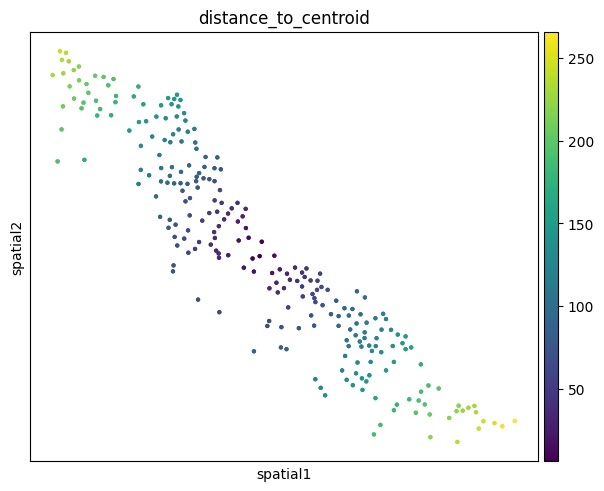

In [47]:
sq.pl.spatial_scatter(
    adata_lesions,
    library_key='group',
    library_id="CWD297",
    shape=None,
    color=["distance_to_centroid" ],
    wspace=0.4,
)
#plt.savefig( './distance_to_centroid.pdf', bbox_inches='tight',  dpi=500)   